# Batch Effect Correction for Multi-sample Spatial Data

### Introduction

When multiple spatial omics samples are analyzed together, technical batch effects may interfere with downstream spatial analysis.

This tutorial demonstrates Harmony-corrected NMF in SpatialZoomer. Following the cNMF strategy described in this [Nature Methods study](https://www.nature.com/articles/s41592-025-02793-1), Harmony first corrects batch effects, the data are converted back to corrected counts with negative values clipped to zero, and NMF is then applied to obtain a batch-corrected embedding.

SpatialZoomer can also use other batch-corrected embeddings, such as Harmony-corrected PCA or scVI, by storing them in `adata.obsm` and passing the corresponding key through `use_rep`.


### Run Harmony-corrected NMF
To compute this representation, set:

```python
adata = sz.performDR(adata, type="NMF_harmony", ...)
```

The corrected embedding is stored in `adata.obsm["X_nmf_harmony"]`. To use it for multiscale spatial analysis, set:

```python
sz_analyzer.multiscale_transform(use_rep="X_nmf_harmony", ...)
```

Install `harmonypy` before running this tutorial:

```bash
pip install harmonypy
```

In [1]:
import warnings
warnings.filterwarnings("ignore")

# Load packages
import spatialzoomer as sz
import numpy as np
import scanpy as sc
import seaborn as sns
import os
import matplotlib.pyplot as plt

# Set figure parameters
plt.rcParams.update({
    "font.family":'sans-serif',
    "mathtext.fontset":'stix',
    "font.size": 7,
    'pdf.fonttype': 42,
    "figure.dpi": 80,     
    "savefig.dpi": 300      
    })
use_dpi = 80 

### Dataset Description

This tutorial uses the Alzheimer’s disease dataset from Figure 2.

The dataset contains six Xenium v1 mouse brain samples profiled with a 347-gene panel: three wild-type samples (`WT1–WT3`) and three TgCRND8 Alzheimer’s disease model samples (`Tg1–Tg3`). The samples represent mild, moderate, and advanced stages of amyloid-beta deposition.

The processed AnnData object can be downloaded from [Google Cloud](https://drive.google.com/file/d/157q4nKFiCu3W6TMgCUhIrkeXA_dBqNdJ/view?usp=drive_link) or from the `Figure2_Xenium_v1_Alzheimers_Disease_Progression` folder on Zenodo repository.

The original dataset is available from the [10x Genomics website](https://www.10xgenomics.com/datasets/xenium-in-situ-analysis-of-alzheimers-disease-mouse-model-brain-coronal-sections-from-one-hemisphere-over-a-time-course-1-standard).

In [2]:
runLabel = 'Xenium_V1_AD_Merged'
save_path = './Outputs/' + runLabel + "_harmony/"
if not os.path.exists(save_path):
    os.makedirs(save_path)
adata_raw = sc.read('Figure2_AD.h5ad')
adata_raw.layers['counts'] = adata_raw.X
adata_raw

AnnData object with n_obs × n_vars = 349063 × 347
    obs: 'cell_id', 'transcript_counts', 'control_probe_counts', 'control_codeword_counts', 'unassigned_codeword_counts', 'total_counts', 'cell_area', 'nucleus_area', 'region', 'cell_labels', 'batch', 'n_genes_by_counts', 'log1p_n_genes_by_counts', 'log1p_total_counts', 'pct_counts_in_top_10_genes', 'pct_counts_in_top_20_genes', 'pct_counts_in_top_50_genes', 'pct_counts_in_top_150_genes', 'n_counts', 'n_genes'
    var: 'n_cells_by_counts', 'mean_counts', 'log1p_mean_counts', 'pct_dropout_by_counts', 'total_counts', 'log1p_total_counts', 'n_cells'
    uns: 'batch_colors'
    obsm: 'spatial', 'spatial_raw'
    layers: 'counts'

The input object should contain:

- the original count expression matrix in `adata.layers['counts']`;
- batch labels in `adata.obs["batch"]`;
- spatial coordinates in `adata.obsm["spatial"]`.

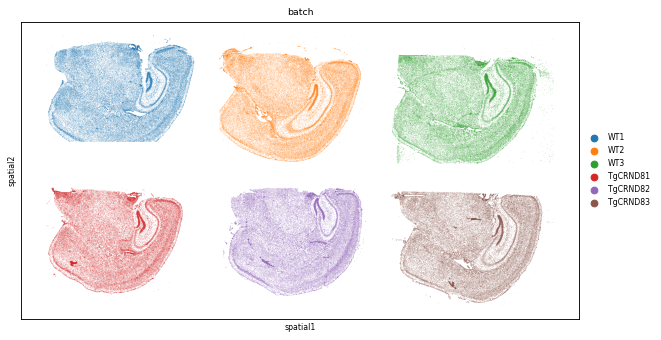

In [3]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(9, 6), dpi= use_dpi)

sc.pl.embedding(
    adata_raw,
    basis="spatial", 
    color="batch",
    ax=ax,
    show=False,
)

ax.set_aspect("equal")
ax.invert_yaxis()      
plt.show()

Set `type="NMF_harmony"` and provide the batch column through `batch_col`. The corrected NMF embedding is stored in `adata.obsm["X_nmf_harmony"]`.

Because Harmony includes stochastic optimization, results may vary slightly between runs.

In [4]:
adata = sz.performDR(adata_raw, type = 'NMF_harmony', batch_col = "batch", n_components=50)
adata

2026-07-05 01:33:33,994 - harmonypy - INFO - Computing initial centroids with sklearn.KMeans...
2026-07-05 01:33:43,286 - harmonypy - INFO - KMeans initialization complete.


Time taken to perform NMF_harmony: 440.3517 seconds


AnnData object with n_obs × n_vars = 349063 × 347
    obs: 'cell_id', 'transcript_counts', 'control_probe_counts', 'control_codeword_counts', 'unassigned_codeword_counts', 'total_counts', 'cell_area', 'nucleus_area', 'region', 'cell_labels', 'batch', 'n_genes_by_counts', 'log1p_n_genes_by_counts', 'log1p_total_counts', 'pct_counts_in_top_10_genes', 'pct_counts_in_top_20_genes', 'pct_counts_in_top_50_genes', 'pct_counts_in_top_150_genes', 'n_counts', 'n_genes'
    var: 'n_cells_by_counts', 'mean_counts', 'log1p_mean_counts', 'pct_dropout_by_counts', 'total_counts', 'log1p_total_counts', 'n_cells'
    uns: 'batch_colors'
    obsm: 'spatial', 'spatial_raw', 'X_nmf_harmony'
    varm: 'nmf_loadings_harmony'
    layers: 'counts'

In [5]:
sz_analyzer = sz.MultiscaleAnalysis(adata=adata, runLabel=runLabel, save_path=save_path)
sz_analyzer.dpi = use_dpi

scales = [0.01] \
    + np.arange(0.1, 2.1, 0.1).tolist() \
    + np.arange(2.5, 15.5, 0.5).tolist() \
    + np.arange(16, 21, 1).tolist() \
    +  np.arange(25, 55, 5).tolist()
scales = [round(x, 2) for x in scales]

Use `X_nmf_harmony` as the input representation for multiscale spatial feature extraction.

Median similarities:  4.999999999984118
Time taken to construct spatial_knn: 2.8287 seconds
Time taken to perform spectral graph filter bank: 173.0825 seconds
Transformed signals saved to ./Outputs/Xenium_V1_AD_Merged_harmony//Xenium_V1_AD_Merged_transformed_signals.h5


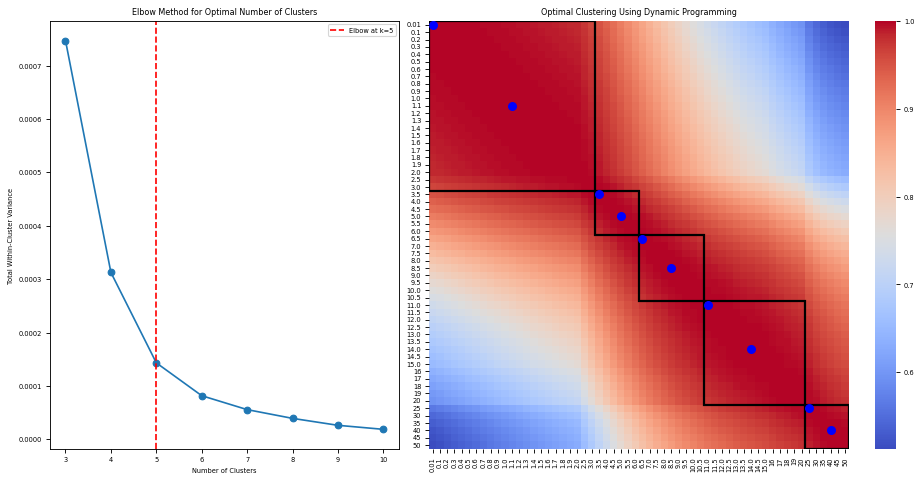

The optimal number of clusters is: 5
Typical scales: [0.01, 1.1, 3.5, 5.0, 6.5, 8.5, 11.0, 14.0, 25, 40]
Time taken to perform identification of typical scales: 20.2414 seconds
Time taken to perform UMAP and clustering for raw signal: 210.3654 seconds
Time taken to perform clustering for signal at scale 0.01: 99.1844 seconds
Time taken to perform clustering for signal at scale 1.1: 100.4954 seconds
Time taken to perform clustering for signal at scale 3.5: 108.8119 seconds
Time taken to perform clustering for signal at scale 5.0: 104.1989 seconds
Time taken to perform clustering for signal at scale 6.5: 94.1061 seconds
Time taken to perform clustering for signal at scale 8.5: 122.4262 seconds
Time taken to perform clustering for signal at scale 11.0: 100.2331 seconds
Time taken to perform clustering for signal at scale 14.0: 104.9895 seconds
Time taken to perform clustering for signal at scale 25.0: 93.6257 seconds
Time taken to perform clustering for signal at scale 40.0: 105.3547 seco

In [6]:
sz_analyzer.multiscale_transform(use_rep='X_nmf_harmony', n_neighbors=20, scales=scales)
sz_analyzer.identify_typical_scales(max_clusters=10, min_clusters=3)
resolutions = [0.8, 1]
sz_analyzer.clustering(n_clusters_kmeans=10000, resolutions=resolutions)
sz_analyzer.adata.write(save_path + runLabel + '_harmony_SpatialZoomer.h5ad')

The single-cell-scale clustering results show consistent cluster patterns across samples.

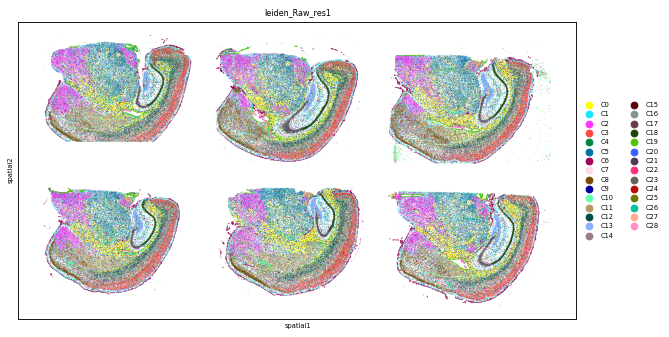

In [7]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(9, 6), dpi= use_dpi)

sc.pl.embedding(
    adata_raw,
    basis="spatial", 
    color="leiden_Raw_res1",
    size=1,
    ax=ax,
    show=False,
)

ax.set_aspect("equal")
ax.invert_yaxis()      
plt.show()

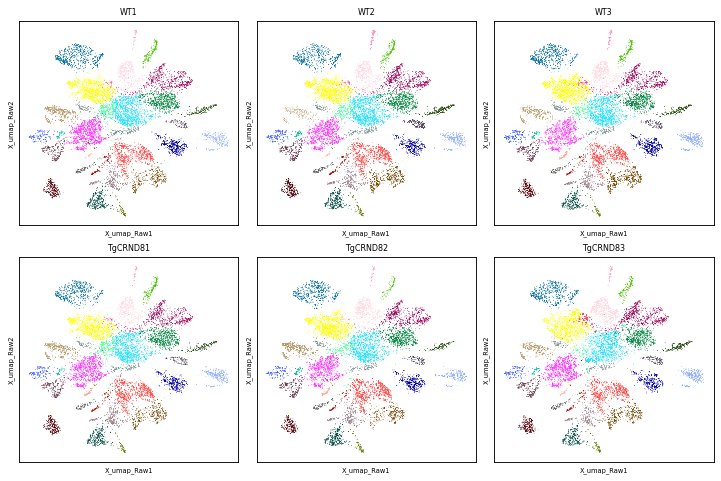

In [ ]:
import matplotlib.pyplot as plt

bs = adata.obs["batch"].unique()
fig, axs = plt.subplots(2, 3, figsize=(9, 6))

for b, ax in zip(bs, axs.flat):  
    sc.pl.embedding(
        adata[adata.obs["batch"] == b],
        basis="X_umap_Raw",
        color="leiden_Raw_res1",
        size=0.5,
        title=str(b),
        legend_loc=None,
        ax=ax,
        show=False,
    )

plt.tight_layout()
plt.show()